# Pair Similarity — Network Mapping & Topological Analysis

This notebook analyzes and maps the network structure defined in `data/out/pair_similarity.parquet`, where edges represent pairwise ideological comparisons between YouTube videos (`id_a` and `id_b`).

### Network Foundations:
* **Nodes ($V$)**: YouTube political videos ($N = 111,967$). Node attributes include `channel`, `title`, and ground-truth ideological `slant` (continuous $[-1.0, +1.0]$).
* **Edges ($E$)**: Pairwise comparisons ($M = 278,000$) evaluated by the LLM teacher model. Edge attributes include:
  * `overall_ideological_alignment`: Degree of political alignment between videos ($-1.0$ to $+1.0$).
  * `overall_ideological_confidence`: Model certainty score.
  * `economic_alignment` & `galtan_alignment`: Multi-dimensional ideological sub-scores.

### Workflow:
1. **Network Construction**: Build global NetworkX graph $G$ connecting `id_a` and `id_b`.
2. **Global Topology & Degree Metrics**: Degree distribution, connected components, and small-world path lengths.
3. **Ideological Homophily & Edge Alignment**: Statistical analysis of in-group vs. cross-ideology alignment distributions.
4. **Macro Channel Network Map**: Aggregated channel-to-channel interaction graph with force-directed layout and ideological coloration.
5. **Micro Video Network Map**: Direct video-to-video connections, cross-ideological bridge, and ego-neighborhood.
6. **Community Detection**: Louvain modularity clustering and comparison with ground truth political slant.
7. **Interactive Video Network Inspector**: Tool to look up any video and inspect its paired neighbors and alignment scores.


In [1]:
import sys
from pathlib import Path

# Add src directory to path
ROOT = Path("../")
sys.path.insert(0, str(ROOT / "src"))

import polars as pl
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
from networkx.algorithms.community import louvain_communities

from config import OUT_DIR

# Aesthetics configuration
sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams["figure.dpi"] = 120


## 1. Load Pair Similarity Data
Read `data/out/pair_similarity.parquet` and inspect edge attributes.


In [2]:
pairs_path = OUT_DIR / "pair_similarity.parquet"
print(f"Reading pair similarities from: {pairs_path}")
pairs = pl.read_parquet(pairs_path)

print(f"Loaded {len(pairs):,} pairwise video connections.")
pairs.select([
    "id_a", "id_b", "channel_a", "channel_b", "title_a", "title_b",
    "slant_a", "slant_b", "overall_ideological_alignment", "overall_ideological_confidence"
]).head(5)


Reading pair similarities from: /Users/gustavidunsloth/Documents/Data Science/youtube-ideology-classifier/nbs/../data/out/pair_similarity.parquet
Loaded 278,000 pairwise video connections.


id_a,id_b,channel_a,channel_b,title_a,title_b,slant_a,slant_b,overall_ideological_alignment,overall_ideological_confidence
str,str,str,str,str,str,f64,f64,f64,f64
"""iWz2bgkmvdk""","""3-JGF1ne8Ec""","""MSNBC""","""Steve Adubato""","""5 Sinema Advisers Resign, Call…","""David Cay Johnston Reveals the…",-0.80723,-0.7799,0.465,0.86
"""3-JGF1ne8Ec""","""zCrcpahiYMM""","""Steve Adubato""","""A&E""","""David Cay Johnston Reveals the…","""Mobsters: New Orleans Mafia Bo…",-0.7799,0.17857,0.0,0.98
"""zCrcpahiYMM""","""1qS9RyEQlS4""","""A&E""","""Senator Josh Hawley""","""Mobsters: New Orleans Mafia Bo…","""Sen. Josh Hawley Questions For…",0.17857,0.73427,-0.005,0.98
"""1qS9RyEQlS4""","""GM22-YY1Fpk""","""Senator Josh Hawley""","""OWN""","""Sen. Josh Hawley Questions For…","""Why the Wayans Brothers' Mom T…",0.73427,-0.93939,-0.09,0.83
"""GM22-YY1Fpk""","""KJ9Ad6s8g7I""","""OWN""","""University of California Telev…","""Why the Wayans Brothers' Mom T…","""Understanding Human Nature wit…",-0.93939,-0.30061,0.325,0.7


## 2. Construct Global Network Graph
Build an undirected NetworkX graph $G=(V, E)$ connecting `id_a` and `id_b` with node and edge attributes.


In [3]:
print("Constructing global NetworkX graph from pairwise edges...")

edges_data = pairs.select([
    "id_a", "id_b", "channel_a", "channel_b", "title_a", "title_b",
    "slant_a", "slant_b", "overall_ideological_alignment", "overall_ideological_confidence",
    "economic_alignment", "galtan_alignment"
]).to_dicts()

G = nx.Graph()
for r in edges_data:
    u, v = r["id_a"], r["id_b"]
    G.add_edge(
        u, v,
        alignment=r["overall_ideological_alignment"],
        confidence=r["overall_ideological_confidence"],
        economic=r["economic_alignment"],
        galtan=r["galtan_alignment"]
    )
    if "channel" not in G.nodes[u]:
        G.nodes[u].update({"channel": r["channel_a"], "title": r["title_a"], "slant": r["slant_a"]})
    if "channel" not in G.nodes[v]:
        G.nodes[v].update({"channel": r["channel_b"], "title": r["title_b"], "slant": r["slant_b"]})

degrees = [d for _, d in G.degree()]
ccs = list(nx.connected_components(G))

print("=" * 70)
print(f"🔹 Nodes (Unique Videos):         {G.number_of_nodes():,}")
print(f"🔹 Edges (Pairwise Comparisons):   {G.number_of_edges():,}")
print(f"🔹 Connected Components:          {len(ccs)} (Largest: {len(max(ccs, key=len)):,})")
print(f"🔹 Degree Distribution:           Mean={np.mean(degrees):.2f}, Median={np.median(degrees):.0f}, Min={min(degrees)}, Max={max(degrees)}")
print("=" * 70)


Constructing global NetworkX graph from pairwise edges...
🔹 Nodes (Unique Videos):         111,967
🔹 Edges (Pairwise Comparisons):   277,995
🔹 Connected Components:          1 (Largest: 111,967)
🔹 Degree Distribution:           Mean=4.97, Median=4, Min=3, Max=6


## 3. Global Topology: Degree & Small-World Hop Distributions
Explore the degree distribution and small-world path length distribution across the 111k-node graph.


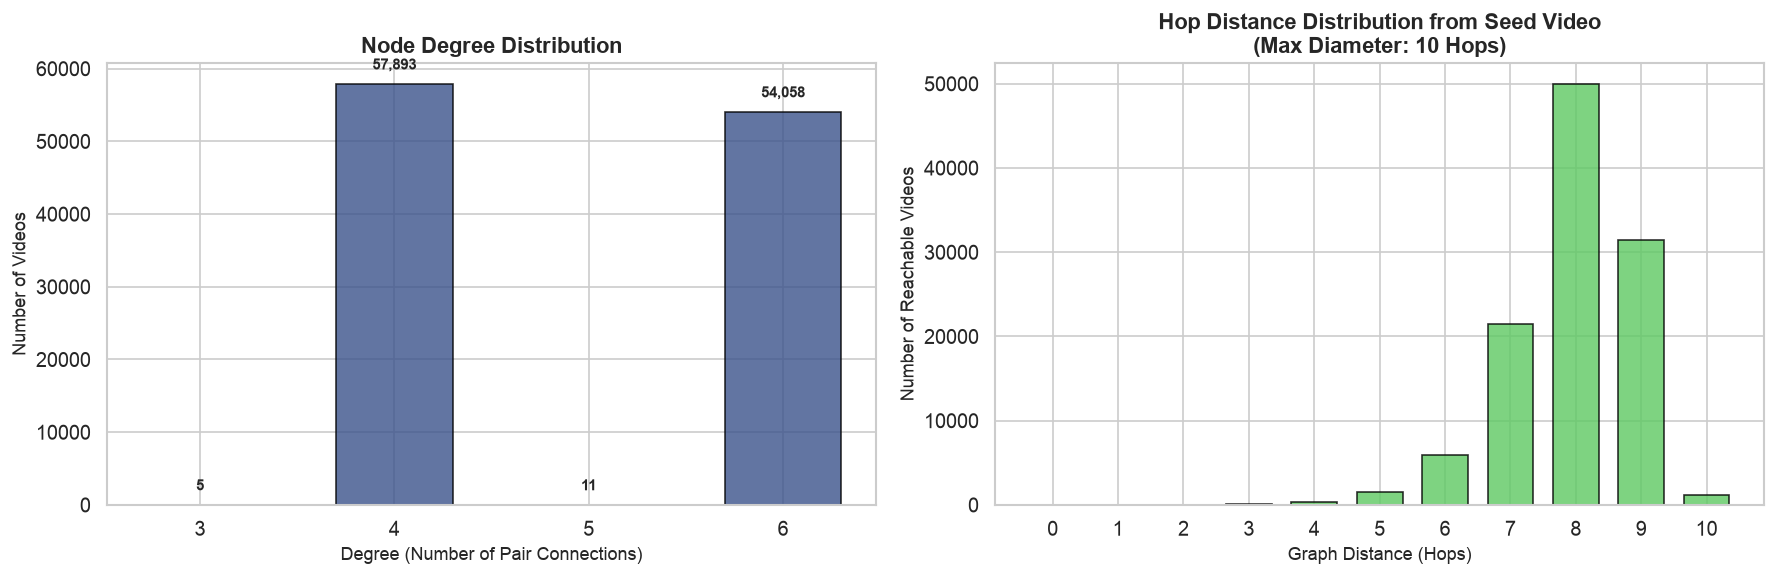

In [4]:
from collections import Counter

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Degree Distribution
deg_counts = Counter(degrees)
deg_x = sorted(deg_counts.keys())
deg_y = [deg_counts[k] for k in deg_x]

axes[0].bar(deg_x, deg_y, color="#3b528b", edgecolor="black", alpha=0.8, width=0.6)
axes[0].set_title("Node Degree Distribution", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Degree (Number of Pair Connections)", fontsize=11)
axes[0].set_ylabel("Number of Videos", fontsize=11)
axes[0].set_xticks(deg_x)
for x, y in zip(deg_x, deg_y):
    axes[0].text(x, y + 2000, f"{y:,}", ha="center", fontsize=9, fontweight="bold")

# 2. Small-World Hop Distance Distribution from Seed Video
seed_sample = list(G.nodes())[0]
hop_lengths = nx.single_source_shortest_path_length(G, seed_sample)
hop_counts = Counter(hop_lengths.values())
hop_x = sorted(hop_counts.keys())
hop_y = [hop_counts[k] for k in hop_x]

axes[1].bar(hop_x, hop_y, color="#5ec962", edgecolor="black", alpha=0.8, width=0.7)
axes[1].set_title(f"Hop Distance Distribution from Seed Video\n(Max Diameter: {max(hop_x)} Hops)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Graph Distance (Hops)", fontsize=11)
axes[1].set_ylabel("Number of Reachable Videos", fontsize=11)
axes[1].set_xticks(hop_x)

plt.tight_layout()
plt.show()


## 4. Ideological Homophily & Edge Alignment Analysis
Examine how model-evaluated pairwise alignment relates to ground-truth ideological slant.
* **Both Left**: $\text{slant}_a < -0.2$ and $\text{slant}_b < -0.2$
* **Both Right**: $\text{slant}_a > +0.2$ and $\text{slant}_b > +0.2$
* **Cross-Ideology (L-R)**: One video is Left ($<-0.2$) and the other is Right ($>+0.2$)
* **Moderate / Neutral**: Videos close to ideological center


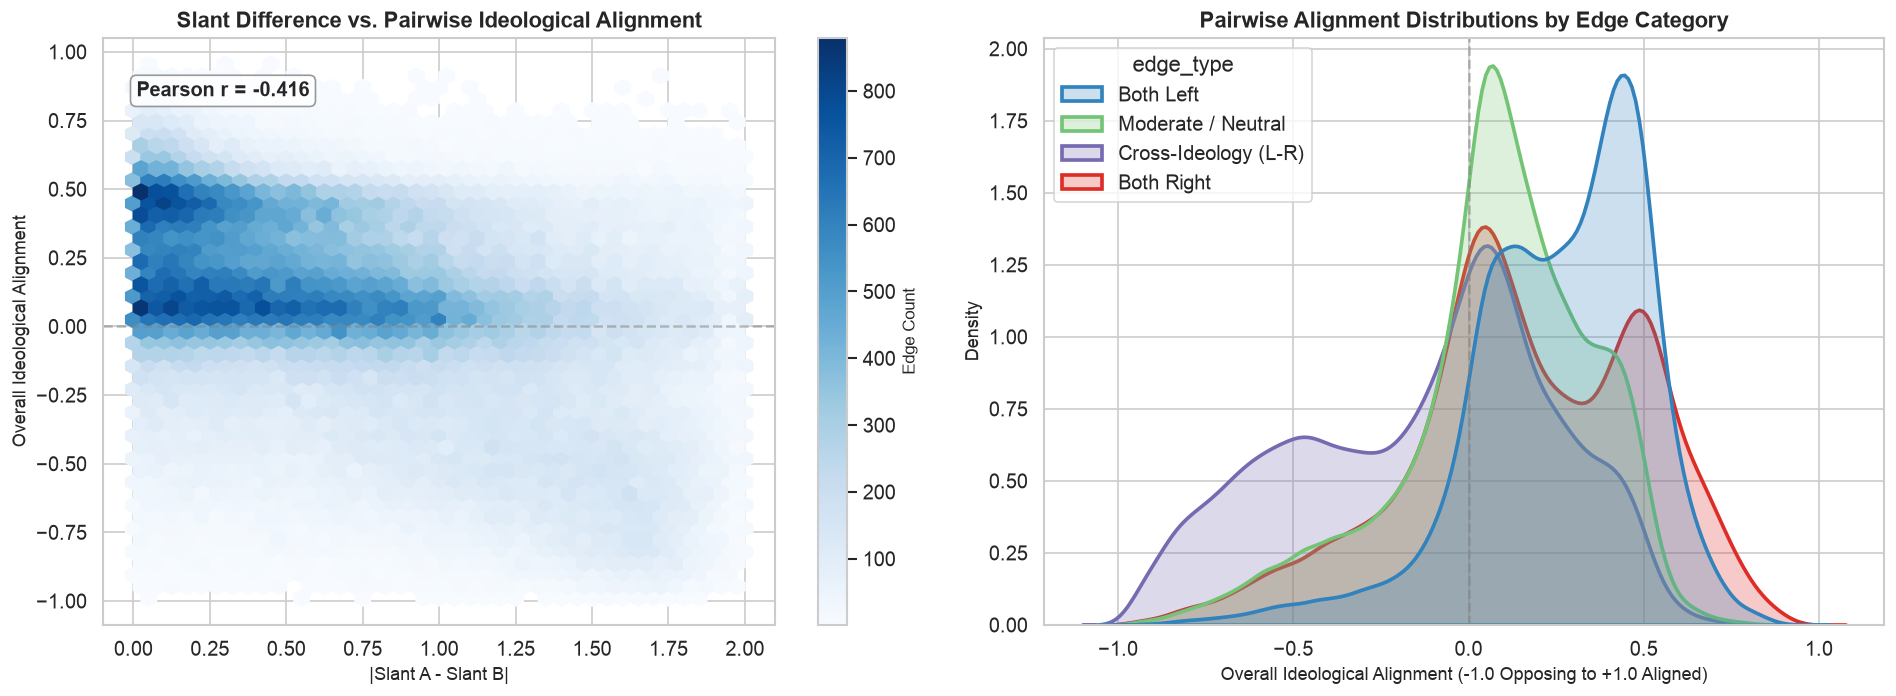


Mean Alignment by Edge Category:
                      alignment  confidence
edge_type                                  
Both Left                 0.263       0.684
Both Right                0.158       0.648
Cross-Ideology (L-R)     -0.125       0.617
Moderate / Neutral        0.079       0.643


In [11]:
slant_a = pairs["slant_a"].to_numpy()
slant_b = pairs["slant_b"].to_numpy()
align = pairs["galtan_alignment"].to_numpy()
conf = pairs["galtan_confidence"].to_numpy()

conditions = []
for a, b in zip(slant_a, slant_b):
    if a < -0.2 and b < -0.2:
        conditions.append("Both Left")
    elif a > 0.2 and b > 0.2:
        conditions.append("Both Right")
    elif (a < -0.2 and b > 0.2) or (a > 0.2 and b < -0.2):
        conditions.append("Cross-Ideology (L-R)")
    else:
        conditions.append("Moderate / Neutral")

df_homophily = pd.DataFrame({
    "edge_type": conditions,
    "alignment": align,
    "confidence": conf,
    "slant_diff": np.abs(slant_a - slant_b)
})

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Hexbin of Slant Difference vs. Ideological Alignment
hb = axes[0].hexbin(
    df_homophily["slant_diff"],
    df_homophily["alignment"],
    gridsize=40,
    cmap="Blues",
    mincnt=1
)
cb = plt.colorbar(hb, ax=axes[0])
cb.set_label("Edge Count", fontsize=10)
axes[0].set_title("Slant Difference vs. Pairwise Ideological Alignment", fontsize=13, fontweight="bold")
axes[0].set_xlabel("|Slant A - Slant B|", fontsize=11)
axes[0].set_ylabel("Overall Ideological Alignment", fontsize=11)
axes[0].axhline(0, color="grey", linestyle="--", alpha=0.5)

corr_diff = np.corrcoef(df_homophily["slant_diff"], df_homophily["alignment"])[0, 1]
axes[0].text(0.05, 0.90, f"Pearson r = {corr_diff:.3f}", transform=axes[0].transAxes,
             fontsize=12, fontweight="bold", bbox=dict(boxstyle="round", fc="white", ec="grey", alpha=0.8))

# Subplot 2: KDE Density Curves by Edge Type
palette = {
    "Both Left": "#3182bd",
    "Both Right": "#de2d26",
    "Moderate / Neutral": "#74c476",
    "Cross-Ideology (L-R)": "#756bb1"
}

sns.kdeplot(
    data=df_homophily,
    x="alignment",
    hue="edge_type",
    palette=palette,
    common_norm=False,
    linewidth=2.2,
    alpha=0.25,
    fill=True,
    ax=axes[1]
)
axes[1].set_title("Pairwise Alignment Distributions by Edge Category", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Overall Ideological Alignment (-1.0 Opposing to +1.0 Aligned)", fontsize=11)
axes[1].set_ylabel("Density", fontsize=11)
axes[1].axvline(0, color="grey", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

print("\nMean Alignment by Edge Category:")
print(df_homophily.groupby("edge_type")[["alignment", "confidence"]].mean().round(3))


## 5. Macro Channel Interaction Network Map
Aggregate the 278,000 video connections into an interconnected **Channel-to-Channel Graph** for the top 32 political channels.
* **Nodes**: Channels (sized by volume, colored by average ideological `slant`: Blue = Left, Red = Right).
* **Edges**: Connections (width by interaction count, colored by average pairwise alignment).
* **Layout**: Force-directed layout revealing political polarization and bridge channels.


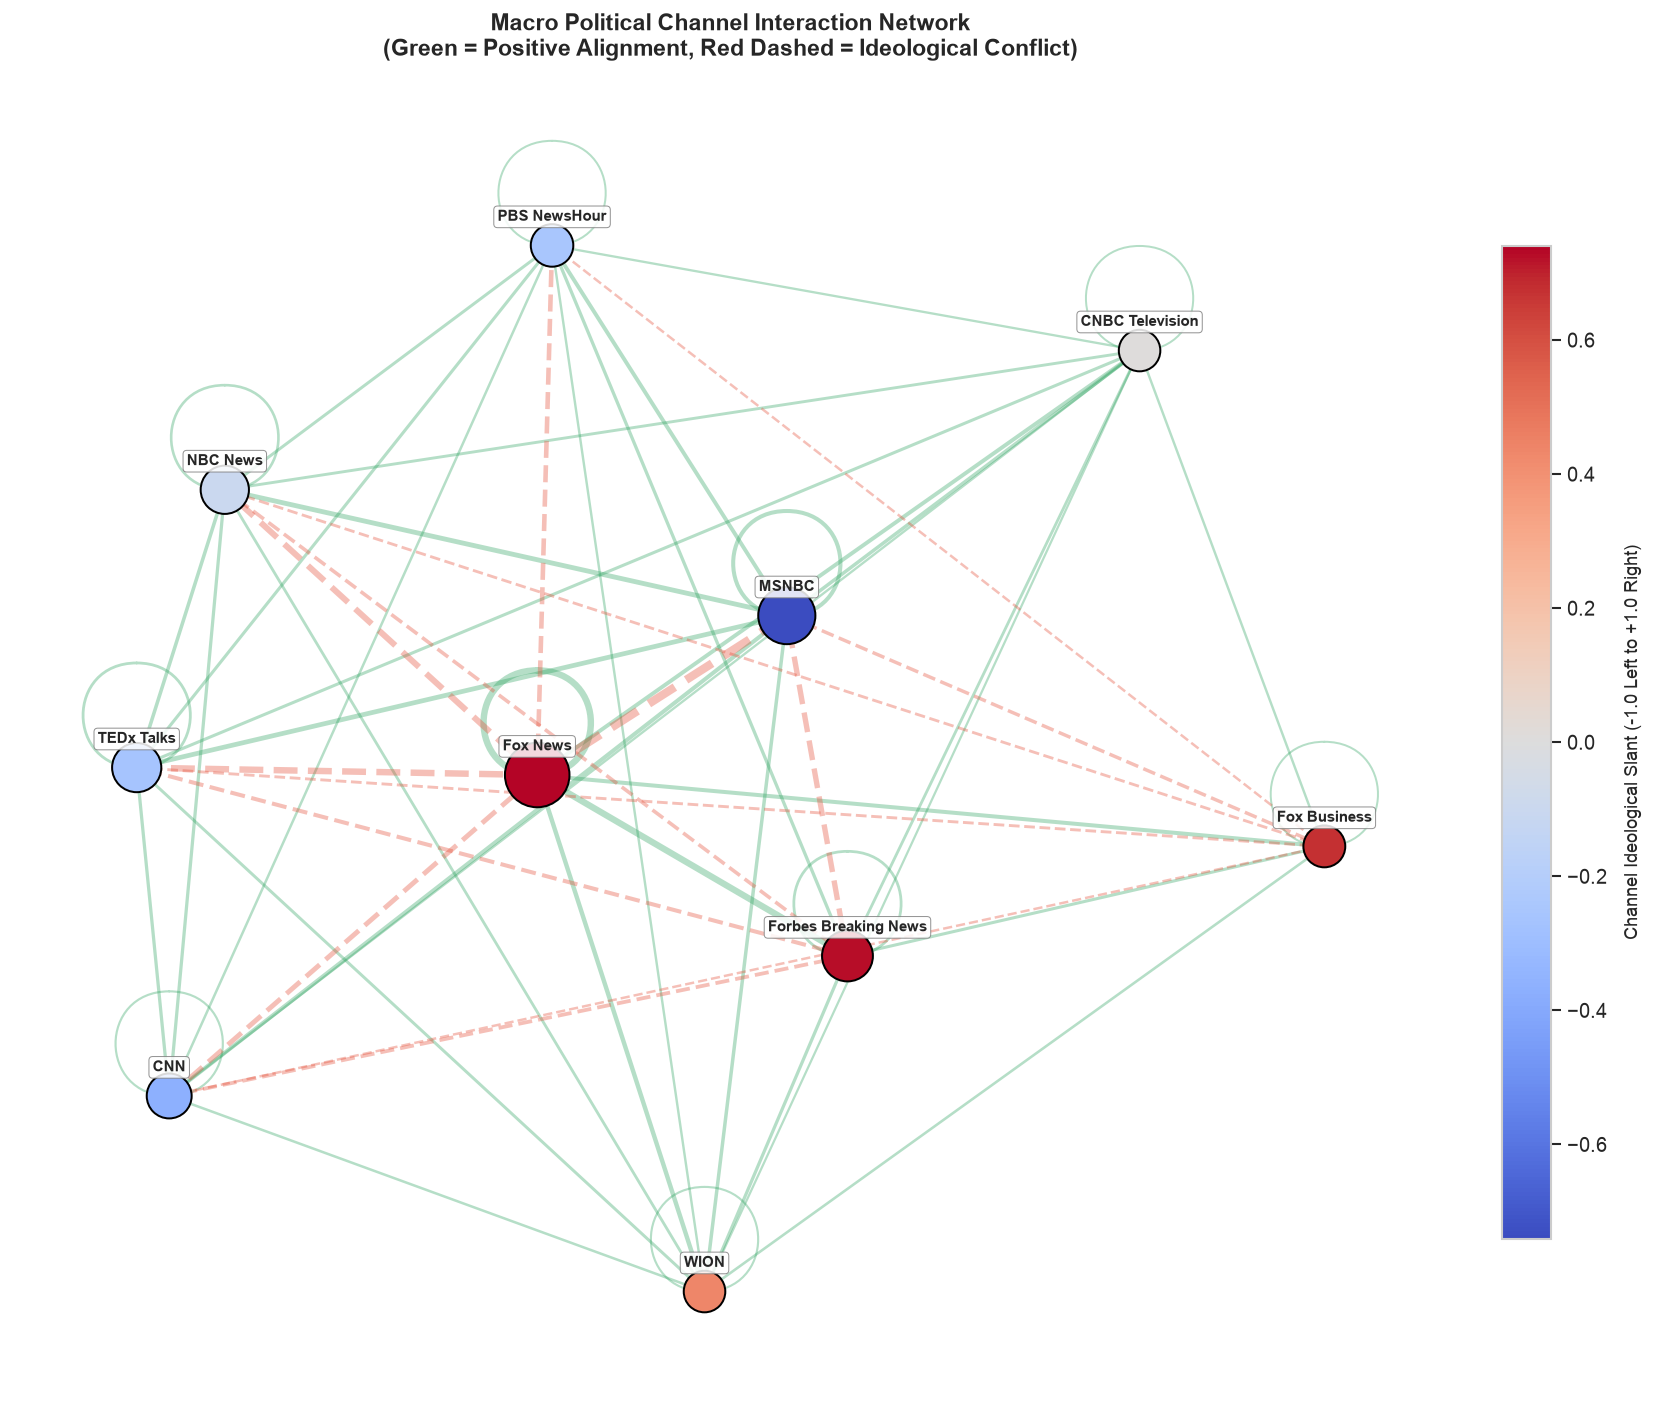

In [10]:
# Filter top channels
top_channels = (
    pairs.group_by("channel_a").agg(pl.len().alias("count"))
    .sort("count", descending=True)
    .head(10)["channel_a"].to_list()
)

ch_pairs = pairs.filter(
    pl.col("channel_a").is_in(top_channels) & pl.col("channel_b").is_in(top_channels)
).group_by(["channel_a", "channel_b"]).agg([
    pl.len().alias("weight"),
    pl.col("overall_ideological_alignment").mean().alias("mean_alignment"),
])

# Build channel graph
G_ch = nx.Graph()
for r in ch_pairs.iter_rows(named=True):
    u, v = r["channel_a"], r["channel_b"]
    w = r["weight"]
    align = r["mean_alignment"]
    if G_ch.has_edge(u, v):
        G_ch[u][v]["weight"] += w
    else:
        G_ch.add_edge(u, v, weight=w, alignment=align)

# Attach channel mean slant and video volume
ch_slants = (
    pairs.group_by("channel_a").agg([
        pl.col("slant_a").mean().alias("slant"),
        pl.len().alias("count")
    ]).to_pandas().set_index("channel_a")
)

for node in G_ch.nodes():
    G_ch.nodes[node]["slant"] = ch_slants.loc[node, "slant"] if node in ch_slants.index else 0.0
    G_ch.nodes[node]["count"] = ch_slants.loc[node, "count"] if node in ch_slants.index else 100

# Compute force-directed layout
pos_ch = nx.spring_layout(G_ch, weight="weight", seed=42, k=0.55, iterations=100)

fig, ax = plt.subplots(figsize=(15, 12))

# 1. Draw Edges
edge_weights = [G_ch[u][v]["weight"] for u, v in G_ch.edges()]
edge_alignments = [G_ch[u][v].get("alignment", 0.0) for u, v in G_ch.edges()]
max_w = max(edge_weights)
widths = [1.0 + 4.0 * (w / max_w) for w in edge_weights]

# Distinct colors: positive alignment (green/solid) vs. negative alignment (coral/dashed)
pos_edges = [(u, v) for u, v in G_ch.edges() if G_ch[u][v].get("alignment", 0.0) >= 0]
neg_edges = [(u, v) for u, v in G_ch.edges() if G_ch[u][v].get("alignment", 0.0) < 0]

nx.draw_networkx_edges(G_ch, pos_ch, edgelist=pos_edges, width=[widths[i] for i, e in enumerate(G_ch.edges()) if e in pos_edges],
                       alpha=0.35, edge_color="#2ca25f", ax=ax)
nx.draw_networkx_edges(G_ch, pos_ch, edgelist=neg_edges, width=[widths[i] for i, e in enumerate(G_ch.edges()) if e in neg_edges],
                       alpha=0.35, edge_color="#e34a33", style="dashed", ax=ax)

# 2. Draw Nodes
node_slants = [G_ch.nodes[n]["slant"] for n in G_ch.nodes()]
node_counts = [G_ch.nodes[n]["count"] for n in G_ch.nodes()]
max_c = max(node_counts)
node_sizes = [300 + 1200 * (c / max_c) for c in node_counts]

nodes_plot = nx.draw_networkx_nodes(
    G_ch, pos_ch,
    node_color=node_slants,
    cmap="coolwarm",
    node_size=node_sizes,
    edgecolors="black",
    linewidths=1.2,
    ax=ax
)

# 3. Draw Labels with background boxes
labels = {n: n for n in G_ch.nodes()}
for n, (x, y) in pos_ch.items():
    ax.text(
        x, y + 0.045, n,
        fontsize=9,
        fontweight="bold",
        ha="center",
        bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="grey", alpha=0.85, lw=0.6)
    )

# Colorbar for Slant
cbar = plt.colorbar(nodes_plot, ax=ax, shrink=0.75, pad=0.03)
cbar.set_label("Channel Ideological Slant (-1.0 Left to +1.0 Right)", fontsize=11, labelpad=10)

ax.set_title(
    "Macro Political Channel Interaction Network\n(Green = Positive Alignment, Red Dashed = Ideological Conflict)",
    fontsize=14, fontweight="bold", pad=15
)
ax.axis("off")
plt.tight_layout()
plt.show()


## 6. Micro Video-Level Network Map: Cross-Ideology Bridge & Ego Subnetwork
Map the direct connections between `id_a` and `id_b` at the video level.
We trace a cross-ideological shortest path and 1-hop neighborhoods connecting a strongly Left-leaning video (MSNBC) to a strongly Right-leaning video (Fox News), visualizing how intermediate videos form ideological bridges.


<>:64: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:64: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
/var/folders/p6/8cdyrdjx0bb9nc27_9f01gpw0000gn/T/ipykernel_64230/2701033017.py:64: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
  f"Video Subnetwork: Cross-Ideological Bridge\n(Bold Path: MSNBC Video [Left] $\leftrightarrow$ Fox News Video [Right])",


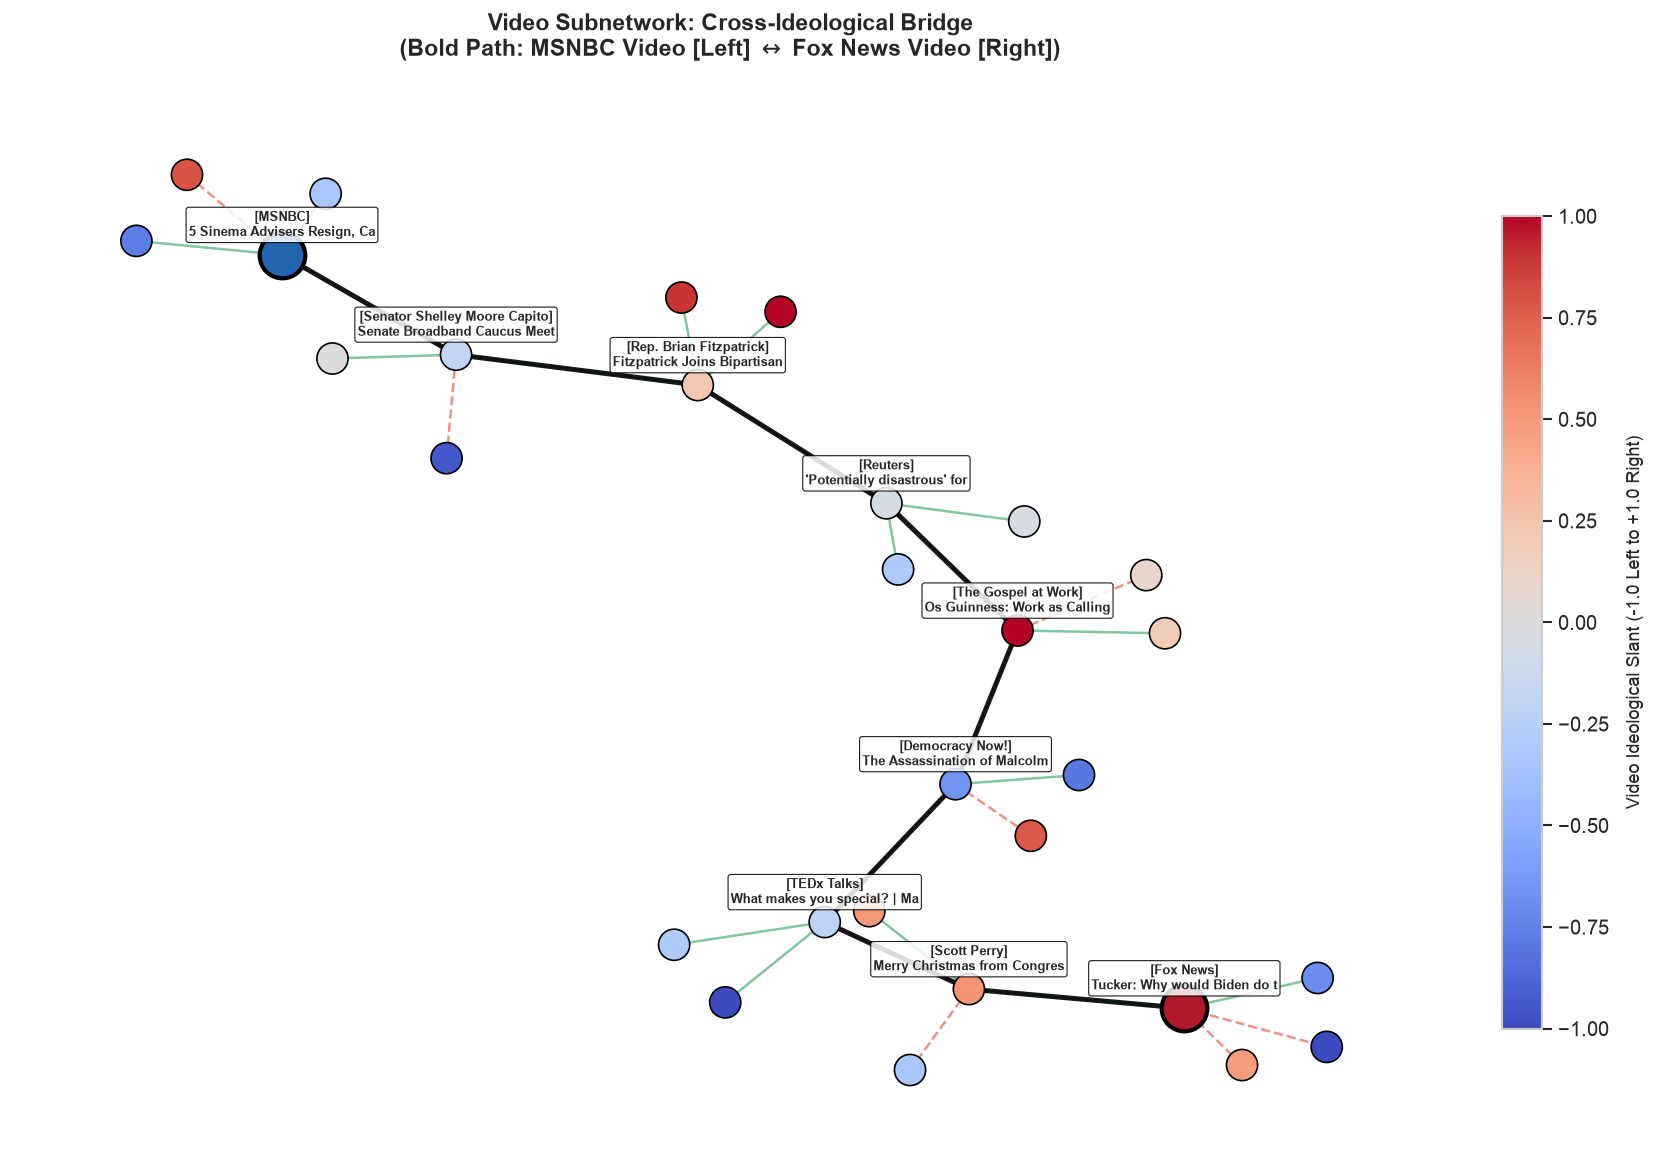

In [7]:
# Find Left and Right seed videos
left_candidates = pairs.filter((pl.col("channel_a") == "MSNBC") & (pl.col("slant_a") < -0.75))["id_a"].to_list()
right_candidates = pairs.filter((pl.col("channel_a") == "Fox News") & (pl.col("slant_a") > 0.75))["id_a"].to_list()

left_seed = left_candidates[0]
right_seed = right_candidates[0]

# Shortest path connecting Left and Right
path_nodes = nx.shortest_path(G, left_seed, right_seed)

# Assemble subnetwork: path nodes + their 1-hop neighbors
sub_nodes = set(path_nodes)
for p in path_nodes:
    sub_nodes.update(list(G.neighbors(p))[:4])  # limit neighbors for clarity

G_sub = G.subgraph(sub_nodes)
pos_sub = nx.spring_layout(G_sub, seed=42, k=0.35, iterations=80)

fig, ax = plt.subplots(figsize=(15, 10))

# 1. Edges
sub_edges = list(G_sub.edges())
pos_sub_edges = [e for e in sub_edges if G_sub[e[0]][e[1]].get("alignment", 0.0) >= 0]
neg_sub_edges = [e for e in sub_edges if G_sub[e[0]][e[1]].get("alignment", 0.0) < 0]

nx.draw_networkx_edges(G_sub, pos_sub, edgelist=pos_sub_edges, edge_color="#2ca25f", width=1.5, alpha=0.6, ax=ax)
nx.draw_networkx_edges(G_sub, pos_sub, edgelist=neg_sub_edges, edge_color="#e34a33", width=1.5, style="dashed", alpha=0.6, ax=ax)

# Highlight shortest path edges
path_edges = list(zip(path_nodes[:-1], path_nodes[1:]))
nx.draw_networkx_edges(G_sub, pos_sub, edgelist=path_edges, edge_color="#000000", width=3.0, alpha=0.9, ax=ax)

# 2. Nodes
sub_slants = [G_sub.nodes[n].get("slant", 0.0) for n in G_sub.nodes()]
node_sub_plot = nx.draw_networkx_nodes(
    G_sub, pos_sub,
    node_color=sub_slants,
    cmap="coolwarm",
    node_size=350,
    edgecolors="black",
    linewidths=1.0,
    ax=ax
)

# Highlight seed endpoints
nx.draw_networkx_nodes(G_sub, pos_sub, nodelist=[left_seed], node_color="#2166ac", node_size=750, edgecolors="black", linewidths=2.5, ax=ax)
nx.draw_networkx_nodes(G_sub, pos_sub, nodelist=[right_seed], node_color="#b2182b", node_size=750, edgecolors="black", linewidths=2.5, ax=ax)

# 3. Label key path videos
for n in path_nodes:
    x, y = pos_sub[n]
    ch = G_sub.nodes[n].get("channel", "Unknown")
    t = G_sub.nodes[n].get("title", "")[:28]
    ax.text(
        x, y + 0.04, f"[{ch}]\n{t}",
        fontsize=8, fontweight="bold", ha="center",
        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="black", alpha=0.85, lw=0.7)
    )

cbar = plt.colorbar(node_sub_plot, ax=ax, shrink=0.75, pad=0.03)
cbar.set_label("Video Ideological Slant (-1.0 Left to +1.0 Right)", fontsize=11, labelpad=10)

ax.set_title(
    f"Video Subnetwork: Cross-Ideological Bridge\n(Bold Path: MSNBC Video [Left] $\leftrightarrow$ Fox News Video [Right])",
    fontsize=14, fontweight="bold", pad=15
)
ax.axis("off")
plt.tight_layout()
plt.show()


## 7. Community Detection (Louvain Modularity)
Apply unsupervised Louvain community detection to determine whether network connectivity naturally partitions into ideological clusters.


/var/folders/p6/8cdyrdjx0bb9nc27_9f01gpw0000gn/T/ipykernel_64230/2696559194.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_comm, x="community", y="slant", palette="Set2", ax=ax, width=0.5)


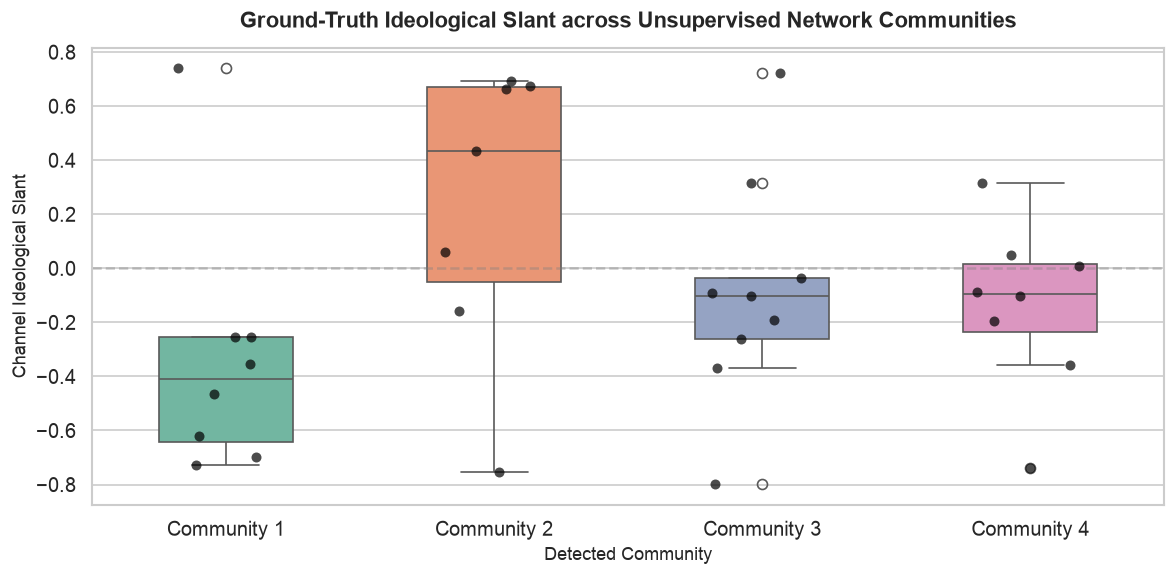


Detected Community Members:

🔹 Community 1 (8 channels, Mean Slant = -0.33):
   Fox News, Guardian News, PBS NewsHour, Saturday Night Live, The Daily Show, The Late Show with Stephen Colbert, VICE News, Vox

🔹 Community 2 (7 channels, Mean Slant = +0.23):
   Al Jazeera English, Bloomberg Television, Democracy Now!, Fox Business, Senator Marco Rubio, Sky News Australia, WION

🔹 Community 3 (9 channels, Mean Slant = -0.09):
   ABC News, BBC News, CNN, DW News, Forbes Breaking News, Reagan Library, Senator Bernie Sanders, TEDx Talks, Washington Post

🔹 Community 4 (8 channels, Mean Slant = -0.14):
   CBS News, CNBC Television, MSNBC, NBC News, Reuters, Sky News, The Hill, The Obama White House


In [8]:
# Run Louvain on Macro Channel Graph
communities = list(louvain_communities(G_ch, weight="weight", seed=42))

comm_data = []
for i, comm in enumerate(communities):
    for ch in comm:
        comm_data.append({
            "channel": ch,
            "community": f"Community {i+1}",
            "slant": G_ch.nodes[ch]["slant"]
        })

df_comm = pd.DataFrame(comm_data)

fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=df_comm, x="community", y="slant", palette="Set2", ax=ax, width=0.5)
sns.stripplot(data=df_comm, x="community", y="slant", color="black", alpha=0.7, size=6, jitter=0.2, ax=ax)

ax.set_title("Ground-Truth Ideological Slant across Unsupervised Network Communities", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Detected Community", fontsize=11)
ax.set_ylabel("Channel Ideological Slant", fontsize=11)
ax.axhline(0, color="grey", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

print("\nDetected Community Members:")
for i, comm in enumerate(communities):
    channels_in_comm = sorted(list(comm))
    mean_s = np.mean([G_ch.nodes[c]["slant"] for c in comm])
    print(f"\n🔹 Community {i+1} ({len(comm)} channels, Mean Slant = {mean_s:+.2f}):")
    print("   " + ", ".join(channels_in_comm))


## 8. Interactive Video Network Inspector
Query any video by ID to inspect its direct connections in the network, paired neighbors, and alignment scores.


In [9]:
def inspect_video_network(video_id: str, max_neighbors: int = 8):
    """Displays focal video metadata and all connected neighbor videos in the pair graph."""
    if video_id not in G:
        print(f"Video ID '{video_id}' not found in network graph!")
        return
    
    node = G.nodes[video_id]
    neighbors = list(G.neighbors(video_id))
    
    print("=" * 95)
    print(f"🎯 FOCAL VIDEO: [{video_id}]")
    print(f"   • Channel: {node.get('channel', 'Unknown')}")
    print(f"   • Title:   {node.get('title', 'Unknown')}")
    print(f"   • Slant:   {node.get('slant', np.nan):+.2f}  |  Total Connections in Corpus: {len(neighbors)}")
    print("=" * 95)
    
    rows = []
    for nbr in neighbors[:max_neighbors]:
        nd = G.nodes[nbr]
        ed = G[video_id][nbr]
        rows.append({
            "Channel": nd.get("channel", "Unknown"),
            "Neighbor Slant": f"{nd.get('slant', np.nan):+.2f}",
            "Overall Align": f"{ed.get('alignment', np.nan):+.2f}",
            "Economic": f"{ed.get('economic', np.nan):+.2f}",
            "GAL-TAN": f"{ed.get('galtan', np.nan):+.2f}",
            "Confidence": f"{ed.get('confidence', np.nan):.2f}",
            "Title": nd.get("title", "Unknown")[:40]
        })
    
    df_nbrs = pd.DataFrame(rows)
    display(df_nbrs)

# Example 1: Left-leaning focal video
inspect_video_network(left_seed)

# Example 2: Right-leaning focal video
inspect_video_network(right_seed)


🎯 FOCAL VIDEO: [iWz2bgkmvdk]
   • Channel: MSNBC
   • Title:   5 Sinema Advisers Resign, Calling Her 'One Of The Principal Obstacles To Progress'
   • Slant:   -0.81  |  Total Connections in Corpus: 5


,Channel,Neighbor Slant,Overall Align,Economic,GAL-TAN,Confidence,Title
0,Steve Adubato,-0.78,+0.47,+0.32,+0.33,0.86,David Cay Johnston Reveals the Real Dona
1,Right Side Broadcasting Network,+0.79,-0.39,-0.82,-0.73,0.32,Congressional Candidate (NH-1) Karoline
2,Senator Shelley Moore Capito,-0.19,-0.04,-0.12,-0.26,0.93,Senate Broadband Caucus Meeting
3,Congressmember Karen Bass,-0.33,+0.44,+0.20,+0.52,0.79,Rep. Karen Bass speaks about HRes 131 an
4,CNN,-0.60,+0.45,+0.09,+0.58,0.80,Guest corrects Joe Rogan live on his own


🎯 FOCAL VIDEO: [Z_0iFBJPWoY]
   • Channel: Fox News
   • Title:   Tucker: Why would Biden do this to his own country?
   • Slant:   +0.86  |  Total Connections in Corpus: 6


,Channel,Neighbor Slant,Overall Align,Economic,GAL-TAN,Confidence,Title
0,Scott Perry,+0.52,+0.51,+0.34,+0.62,0.88,Merry Christmas from Congressman Scott P
1,TEDx Talks,+0.49,-0.01,-0.08,-0.43,0.97,"Blockchain, the future of money | Nicola"
2,TaosInstitute,-1.00,-0.12,-0.20,-0.86,0.78,Ken Gergen - Beyond the Therapeutic Stat
3,lol Valley,-0.69,+0.00,+0.03,-0.14,0.97,Peter Gregory Hates College - Silicon Va
4,M4NTICOR3,-0.10,+0.17,+0.00,-0.05,0.53,WASHINGTONWORMHOLE | The Monument Mythos
5,Vox,+0.35,-0.03,-0.10,-0.57,0.94,Filthy Frank fans made us do this
